# Đánh giá Wide ResNet-16-4 trên CIFAR-100

Notebook đọc hai file training history trong `checkpoints/`, vẽ biểu đồ trước, rồi đánh giá checkpoint 200 epoch trên tập test CIFAR-100. Lượt 200 epoch có thể dừng sớm nên số dòng CSV có thể ít hơn 200. Checkpoint này được chọn theo **validation loss thấp nhất**. Tập test không được dùng để chọn checkpoint.

Chạy các cell theo thứ tự từ trên xuống. Cần có `tensorflow`, `numpy`, `pandas`, `matplotlib`, `h5py`, `scikit-learn` và dữ liệu gốc trong `cifar-100/`.

## 1. Đọc và vẽ training history

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_DIR = next(
    (path.resolve() for path in (Path.cwd(), Path.cwd().parent)
     if (path / "checkpoints" / "cifar100_wrn16_4_aug200_history.csv").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Không tìm thấy checkpoints/; hãy chạy notebook từ thư mục project.")

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
EVALUATION_DIR = PROJECT_DIR / "evaluation"
EVALUATION_DIR.mkdir(exist_ok=True)
HISTORY_FILES = {
    "20 epoch": CHECKPOINT_DIR / "cifar100_wrn16_4_aug20_history.csv",
    "200 epoch (early stopping)": CHECKPOINT_DIR / "cifar100_wrn16_4_aug200_history.csv",
}
REQUIRED_COLUMNS = {"epoch", "accuracy", "loss", "val_accuracy", "val_loss"}
histories = {}
for name, path in HISTORY_FILES.items():
    if not path.is_file():
        raise FileNotFoundError(f"Không tìm thấy history: {path}")
    history = pd.read_csv(path)
    missing = REQUIRED_COLUMNS.difference(history.columns)
    if missing:
        raise ValueError(f"{path.name} thiếu cột: {sorted(missing)}")
    if history.empty:
        raise ValueError(f"History rỗng: {path}")
    history["epoch_number"] = history["epoch"].astype(int) + 1
    histories[name] = history
    print(f"{name}: {len(history)} epoch — {path.name}")

def plot_training_history(history, title, best_metric, output_name):
    epoch = history["epoch_number"]
    best_row = history.loc[history[best_metric].idxmax() if best_metric == "val_accuracy"
                           else history[best_metric].idxmin()]
    best_epoch = int(best_row["epoch_number"])
    fig, (accuracy_ax, loss_ax) = plt.subplots(1, 2, figsize=(14, 4.5))
    accuracy_ax.plot(epoch, history["accuracy"] * 100, label="Train", color="#3678b9")
    accuracy_ax.plot(epoch, history["val_accuracy"] * 100, label="Validation", color="#e58232")
    loss_ax.plot(epoch, history["loss"], label="Train", color="#3678b9")
    loss_ax.plot(epoch, history["val_loss"], label="Validation", color="#e58232")
    for ax in (accuracy_ax, loss_ax):
        ax.axvline(best_epoch, color="#37966e", linestyle="--", alpha=0.8,
                   label=f"Checkpoint: epoch {best_epoch}")
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.25)
        ax.legend()
    accuracy_ax.set(title="Accuracy", ylabel="Accuracy (%)")
    loss_ax.set(title="Loss", ylabel="Cross-entropy loss")
    fig.suptitle(title, fontsize=15)
    fig.tight_layout()
    output_path = EVALUATION_DIR / output_name
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Đã lưu biểu đồ: {output_path}")


20 epoch: 20 epoch — cifar100_wrn16_4_aug20_history.csv
200 epoch (early stopping): 94 epoch — cifar100_wrn16_4_aug200_history.csv


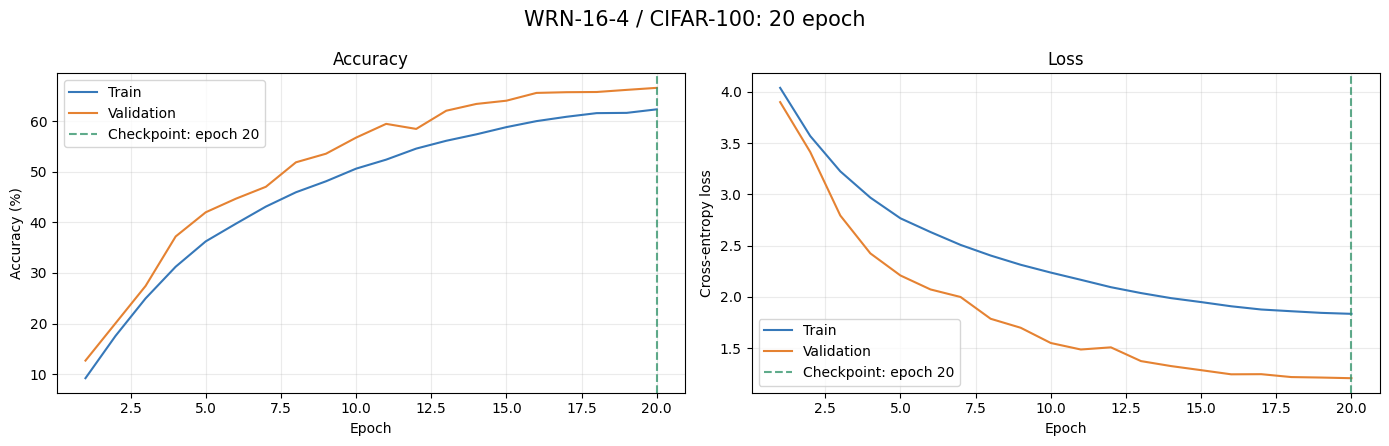

Đã lưu biểu đồ: /Users/bach/Downloads/AI Projects/fruit-detection/evaluation/wrn_training_history_20.png


In [2]:
plot_training_history(
    histories["20 epoch"],
    "WRN-16-4 / CIFAR-100: 20 epoch",
    best_metric="val_accuracy",
    output_name="wrn_training_history_20.png",
)

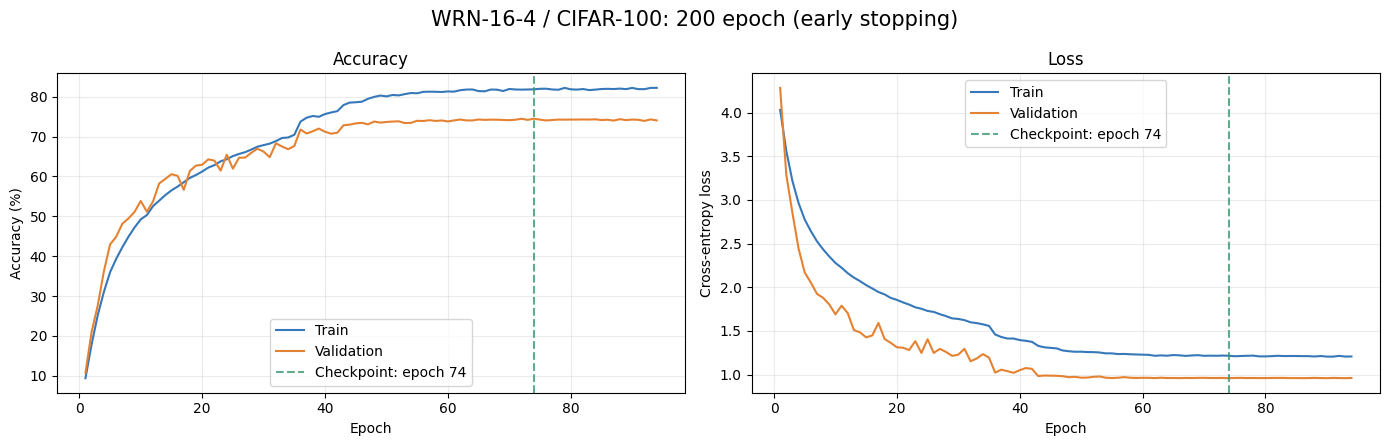

Đã lưu biểu đồ: /Users/bach/Downloads/AI Projects/fruit-detection/evaluation/wrn_training_history_200.png


In [3]:
plot_training_history(
    histories["200 epoch (early stopping)"],
    "WRN-16-4 / CIFAR-100: 200 epoch (early stopping)",
    best_metric="val_loss",
    output_name="wrn_training_history_200.png",
)

In [4]:
summary_rows = []
for name, history in histories.items():
    best = history.loc[history["val_accuracy"].idxmax()] if name.startswith("20") else history.loc[history["val_loss"].idxmin()]
    summary_rows.append({
        "Lượt train": name,
        "Số epoch đã chạy": len(history),
        "Epoch checkpoint": int(best["epoch_number"]),
        "Val accuracy (%)": round(float(best["val_accuracy"]) * 100, 2),
        "Val loss": round(float(best["val_loss"]), 4),
    })
display(pd.DataFrame(summary_rows))

,Lượt train,Số epoch đã chạy,Epoch checkpoint,Val accuracy (%),Val loss
0,20 epoch,20,20,66.60,1.2071
1,200 epoch (early stopping),94,74,74.48,0.9590


Train accuracy chỉ để tham khảo vì quá trình train dùng MixUp/CutMix và nhãn mềm. Validation accuracy/loss được tính trên ảnh không augmentation.

## 2. Nạp checkpoint WRN

Ưu tiên nạp `.keras` trực tiếp. Nếu checkpoint Keras 2.15 không tương thích với Keras 3, notebook dựng lại đúng kiến trúc trong `build_wrn_cifar_100.ipynb`, sửa đường dẫn nhóm trọng số Windows trong file HDF5 tạm, rồi nạp toàn bộ trọng số. Không chỉnh sửa checkpoint gốc.

In [5]:
import json
import pickle
import tempfile
import zipfile

import h5py
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, top_k_accuracy_score

NUM_CLASSES = 100
IMAGE_SIZE = 32
BATCH_SIZE = 64
SEED = 42
VALIDATION_SIZE = 5_000
CHECKPOINT_PATH = CHECKPOINT_DIR / "cifar100_wrn16_4_aug200_best.keras"
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Không tìm thấy checkpoint: {CHECKPOINT_PATH}")


def build_wrn_16_4():
    layers = tf.keras.layers

    def block(inputs, channels, stride):
        x = layers.BatchNormalization()(inputs)
        x = layers.Activation("relu")(x)
        shortcut = inputs
        if stride != 1 or inputs.shape[-1] != channels:
            shortcut = layers.Conv2D(channels, 1, strides=stride, padding="same", use_bias=False)(inputs)
        x = layers.Conv2D(channels, 3, strides=stride, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Conv2D(channels, 3, padding="same", use_bias=False)(x)
        return layers.Add()([shortcut, x])

    inputs = tf.keras.Input((IMAGE_SIZE, IMAGE_SIZE, 3))
    x = layers.Conv2D(16, 3, padding="same", use_bias=False)(inputs)
    for channels, first_stride in ((64, 1), (128, 2), (256, 2)):
        x = block(x, channels, first_stride)
        x = block(x, channels, 1)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return tf.keras.Model(inputs, outputs, name="wrn_16_4_cifar100")


def load_wrn_checkpoint(path):
    try:
        model = tf.keras.models.load_model(str(path), compile=False)
        print("Đã nạp checkpoint trực tiếp.")
        return model
    except (TypeError, ValueError) as error:
        print(f"Nạp trực tiếp chưa tương thích ({type(error).__name__}); đang chuyển đường dẫn trọng số trong bộ nhớ tạm.")

    model = build_wrn_16_4()
    with tempfile.TemporaryDirectory(prefix="wrn-checkpoint-") as temp_dir:
        weights_path = Path(temp_dir) / "compatible.weights.h5"
        with zipfile.ZipFile(path) as archive:
            if "model.weights.h5" not in archive.namelist():
                raise ValueError(f"Checkpoint không chứa model.weights.h5: {path}")
            original_path = Path(temp_dir) / "original.h5"
            original_path.write_bytes(archive.read("model.weights.h5"))

        with h5py.File(original_path, "r") as source, h5py.File(weights_path, "w") as target:
            def copy_item(name, item):
                # Keras 2.15 trên Windows lưu các nhóm dưới tên chứa dấu backslash.
                name = name.replace("\\", "/")
                if isinstance(item, h5py.Group):
                    output = target.require_group(name)
                else:
                    parent, _, leaf = name.rpartition("/")
                    output = target.require_group(parent).create_dataset(
                        leaf, data=item[()], dtype=item.dtype
                    )
                for key, value in item.attrs.items():
                    output.attrs[key] = value
            source.visititems(copy_item)
        model.load_weights(str(weights_path))
    print("Đã nạp đủ trọng số vào kiến trúc WRN-16-4.")
    return model


model = load_wrn_checkpoint(CHECKPOINT_PATH)
assert model.input_shape == (None, 32, 32, 3)
assert model.output_shape == (None, 100)
print(f"Checkpoint: {CHECKPOINT_PATH.name} | Parameters: {model.count_params():,}")

Nạp trực tiếp chưa tương thích (TypeError); đang chuyển đường dẫn trọng số trong bộ nhớ tạm.


Đã nạp đủ trọng số vào kiến trúc WRN-16-4.
Checkpoint: cifar100_wrn16_4_aug200_best.keras | Parameters: 2,775,636


## 3. Chuẩn bị test set

Dùng lại đúng phép chia seed 42: lấy 5.000 ảnh đầu của hoán vị làm validation, tính mean/std trên 45.000 ảnh train còn lại. Ảnh test chỉ được chuẩn hóa bằng mean/std này, không augmentation.

In [6]:
DATA_DIR = PROJECT_DIR / "cifar-100"
for filename in ("train", "test", "meta"):
    if not (DATA_DIR / filename).is_file():
        raise FileNotFoundError(f"Không tìm thấy {DATA_DIR / filename}")


def read_batch(path):
    with path.open("rb") as stream:
        batch = pickle.load(stream, encoding="bytes")
    images = np.asarray(batch[b"data"], dtype=np.uint8).reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1).copy()
    labels = np.asarray(batch[b"fine_labels"], dtype=np.int32)
    return images, labels


train_images, _ = read_batch(DATA_DIR / "train")
test_images, test_labels = read_batch(DATA_DIR / "test")
with (DATA_DIR / "meta").open("rb") as stream:
    class_names = [name.decode("utf-8") for name in pickle.load(stream, encoding="bytes")[b"fine_label_names"]]
assert len(class_names) == NUM_CLASSES
train_indices = np.random.default_rng(SEED).permutation(len(train_images))[VALIDATION_SIZE:]
train_for_stats = train_images[train_indices]
train_mean = train_for_stats.mean(axis=(0, 1, 2), dtype=np.float64) / 255.0
train_std = train_for_stats.std(axis=(0, 1, 2), dtype=np.float64) / 255.0
del train_images, train_for_stats
print(f"Train mean: {train_mean} | std: {train_std}")
print(f"Test set: {len(test_labels):,} ảnh, {len(class_names)} lớp")

mean_tf = tf.constant(train_mean, dtype=tf.float32)
std_tf = tf.constant(train_std, dtype=tf.float32)
test_ds = (
    tf.data.Dataset.from_tensor_slices(test_images)
    .map(lambda image: (tf.cast(image, tf.float32) / 255.0 - mean_tf) / std_tf,
         num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

Train mean: [0.50709441 0.48648463 0.44073288] | std: [0.26716948 0.25635508 0.27603568]
Test set: 10,000 ảnh, 100 lớp


## 4. Đánh giá trên test set

Một lượt suy luận cho toàn bộ ảnh test; tính cross-entropy, top-1, top-5 và báo cáo precision/recall/F1 theo lớp. Kết quả lưu trong `evaluation/`.

In [7]:
probabilities = model.predict(test_ds, verbose=0)
if probabilities.shape != (len(test_labels), NUM_CLASSES):
    raise ValueError(f"Kích thước dự đoán không đúng: {probabilities.shape}")
predictions = probabilities.argmax(axis=1)
test_loss = float(tf.reduce_mean(
    tf.keras.losses.sparse_categorical_crossentropy(test_labels, probabilities)
).numpy())
test_accuracy = float(np.mean(predictions == test_labels))
test_top5 = float(top_k_accuracy_score(
    test_labels, probabilities, k=5, labels=np.arange(NUM_CLASSES)
))
report = classification_report(
    test_labels, predictions, labels=np.arange(NUM_CLASSES), target_names=class_names,
    output_dict=True, zero_division=0,
)
metrics = {
    "checkpoint": CHECKPOINT_PATH.name,
    "test_samples": int(len(test_labels)),
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "test_top5_accuracy": test_top5,
    "macro_precision": float(report["macro avg"]["precision"]),
    "macro_recall": float(report["macro avg"]["recall"]),
    "macro_f1": float(report["macro avg"]["f1-score"]),
}
metrics_path = EVALUATION_DIR / "wrn_test_metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
report_path = EVALUATION_DIR / "wrn_classification_report.csv"
report_df = pd.DataFrame(report).T
report_df.to_csv(report_path, index_label="class")
print(f"Test loss: {test_loss:.4f} | Top-1: {test_accuracy:.2%} | Top-5: {test_top5:.2%} | Macro F1: {metrics['macro_f1']:.4f}")
print(f"Đã lưu: {metrics_path.name}, {report_path.name}")
display(report_df.loc[class_names].sort_values("f1-score").head(15))

Test loss: 0.9530 | Top-1: 74.05% | Top-5: 93.13% | Macro F1: 0.7397
Đã lưu: wrn_test_metrics.json, wrn_classification_report.csv


,precision,recall,f1-score,support
otter,0.436170,0.41,0.422680,100.0
girl,0.506024,0.42,0.459016,100.0
shrew,0.456311,0.47,0.463054,100.0
seal,0.466019,0.48,0.472906,100.0
boy,0.505051,0.50,0.502513,100.0
lizard,0.531250,0.51,0.520408,100.0
woman,0.523810,0.55,0.536585,100.0
man,0.566667,0.51,0.536842,100.0
snake,0.527778,0.57,0.548077,100.0
bowl,0.560000,0.56,0.560000,100.0


## 5. Ma trận nhầm lẫn

Biểu đồ chuẩn hóa theo nhãn thật để thấy tỷ lệ đúng/sai của từng lớp. CSV lưu số lượng gốc cho đủ 100 lớp.

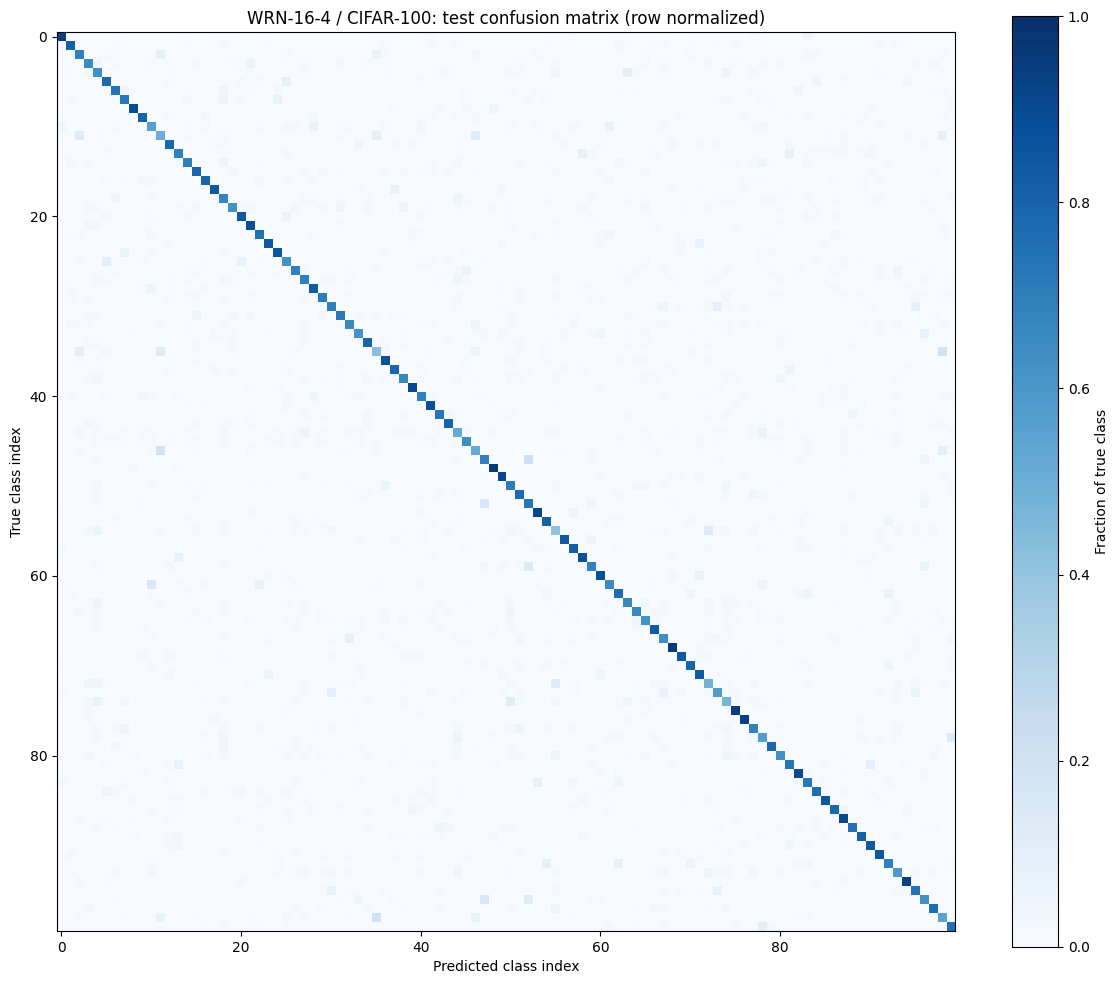

Đã lưu: wrn_confusion_matrix.csv, wrn_confusion_matrix.png


In [8]:
cm = confusion_matrix(test_labels, predictions, labels=np.arange(NUM_CLASSES))
cm_path = EVALUATION_DIR / "wrn_confusion_matrix.csv"
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(cm_path, index_label="true/predicted")
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm_normalized, cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
ax.set(title="WRN-16-4 / CIFAR-100: test confusion matrix (row normalized)",
       xlabel="Predicted class index", ylabel="True class index")
fig.colorbar(im, ax=ax, label="Fraction of true class")
fig.tight_layout()
cm_plot_path = EVALUATION_DIR / "wrn_confusion_matrix.png"
fig.savefig(cm_plot_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Đã lưu: {cm_path.name}, {cm_plot_path.name}")